# Variables aleatorias (absolutamente) continuas

**Definición.** Una variable aleatoria absolutamente continua es aquella para la cual existe una función $f_X$ no negativa, llamada función de densidad, tal que:
$$
F_X(x) = \mathbb{P}(X\leq x) = \int_{-\infty}^{x} f_X(y) dy, \quad x\in \mathbb{R}
$$

**Lema.** Sea $F_X$ una función de distribución. Supongamos que $F_X$ es derivable y que su derivada es continua en $(a, b)$, donde:
$ a = \inf \{ x \in \mathbb{R} \mid F_X(x) > 0 \}, \quad b = \sup \{ x \in \mathbb{R} \mid F_X(x) < 1 \}$
entonces, la función de densidad se puede obtener como:
$$ f_X(x) =
\begin{cases}
F'_X(x), & \text{si } x \in (a, b), \\
0, & \text{e.o.c.}
\end{cases}$$

Es decir,
$$ \frac{dF_X(x)}{dx} = f_X(x)$$


In [1]:
import numpy as np # Importamos Numpy
import numpy.random as npr # para generar numeros aleatorios

import scipy.stats as sps # Importamos el modulo SciPy
from scipy.stats import randint # para trabajar una uniforme discreta en un rango de enteros

import matplotlib.pyplot as plt #Visualizar datos

import random # para generar numeros aleatorios

## Variable aleatoria uniforme (rectangular) sobre el intervalo $(a,b)$.

Una variable aleatoria $X$ se dice que tiene distribución uniforme continua  en el intervalo $(a,b)$ con $a,b\in\mathbb{R}$, si su función de densidad esta dada por:
$$f_{X}(x)=\begin{cases}
	\frac{1}{b-a} &\quad \text{si } a< x < b\\
	\qquad 0 &\quad \text{en otro caso}  
\end{cases}$$

**Notación.** $X\sim \text{Unif}(a,b)$ $\text{Unif}[a,b]$

**Obs:**
* La distribución uniforme continua en $(a,b)$ es simétrica.
* A los intervalos de la misma longitud contenidos en $(a,b)$ se les asigna la misma probabilidad. Esto se representa gráficamente con la probabilidad de que $X$ se encuentre en el intervalo $(s,t)$:


La función de distribución de $X\sim Unif((a,b))$ esta dada por:
$$F_{X}(x)=\begin{cases}
	 0 &\quad \text{si } x\le a \\
	\frac{x-a}{b-a} &\quad \text{si } a<x<b\\
	 1 &\quad \text{si } x\ge b  
\end{cases}$$

La esperanza de una variable aleatoria uniforme es la siguiente,
$$\begin{align*}
\mathbb{E}[X] &= \int_{a}^{b}xf_{X}(x)dx = \int_{a}^{b}x\frac{1}{b-a}dx = \frac{1}{b-a}\int_{a}^{b}xdx  = \frac{1}{b-a}\left[\frac{x^{2}}{2}\right]_{a}^{b} \\ &= \frac{1}{b-a}\left[\frac{b^{2}}{2}-\frac{a^{2}}{2}\right] =  \frac{b^{2}-a^{2}}{2(b-a)} = \frac{(b-a)(b+a)}{2(b-a)} = \frac{a+b}{2}.
\end{align*}$$

Para calcular la varianza, primero vamos a calcular el segundo momento
$$\begin{align*}
\mathbb{E}[X^{2}] &= \int_{a}^{b}x^{2}f_{X}(x)dx = \int_{a}^{b}x^{2}\frac{1}{b-a}dx = \frac{1}{b-a}\int_{a}^{b}x^{2}dx \\ &= \frac{1}{b-a}\left[\frac{x^{3}}{3}\right]_{a}^{b} = \frac{1}{b-a}\left[\frac{b^{3}}{3}-\frac{a^{3}}{3}\right] =  \frac{b^{3}-a^{3}}{3(b-a)}.
\end{align*}$$

Por lo que se tiene lo siguiente

$$Var(X) = \mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} =\frac{b^{3}-a^{3}}{3(b-a)}-\left(\frac{a+b}{2}\right)^{2} = \frac{(b-a)^{2}}{12}.$$

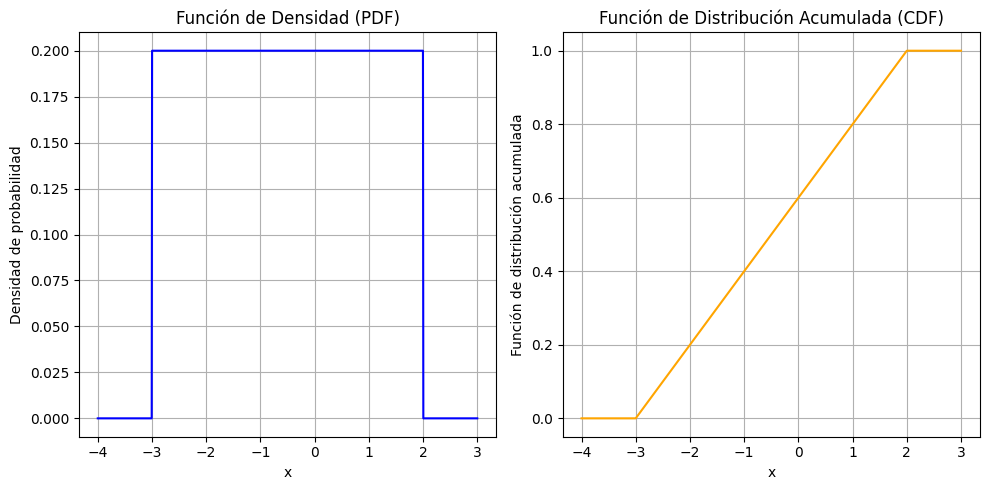

In [2]:
# Parámetros de la distribución uniforme
a = -3  # límite inferior
b = 2  # límite superior

# Definimos las funciones de densidad y distribución
# Función de densidad (pdf) de la distribución uniforme
def uniform_pdf(x, a, b):
    return np.where((x >= a) & (x <= b), 1 / (b - a), 0)

# Función de distribución (cdf) de la distribución uniforme
def uniform_cdf(x, a, b):
    return np.where(x < a, 0, np.where(x > b, 1, (x - a) / (b - a)))

# Generar valores de x
x = np.linspace(-4, 3, 1000)

# Calcular la función densidad
pdf_values = uniform_pdf(x, a, b)

# Calcular la función de distribución
cdf_values = uniform_cdf(x, a, b)

# Graficar la PDF
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1) # para poner gráficas juntas
plt.plot(x, pdf_values, label='PDF', color='blue') # para cada gráfica
plt.xlabel('x')
plt.ylabel('Densidad de probabilidad')
plt.title('Función de Densidad (PDF)')
plt.grid(True)

# Graficar la CDF
plt.subplot(1, 2, 2)
plt.plot(x, cdf_values, label='CDF', color='orange')
plt.xlabel('x')
plt.ylabel('Función de distribución acumulada')
plt.title('Función de Distribución Acumulada (CDF)')
plt.grid(True)

plt.tight_layout()
plt.show()

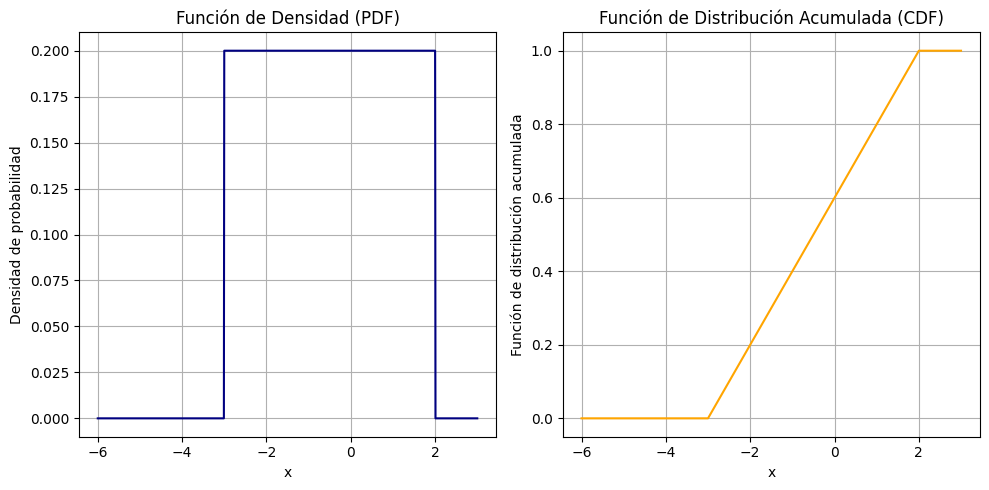

In [7]:
# Realizar las graficas de la densidad y distrobución de la uniforma continua
from scipy.stats import uniform
# Parámetros de la distribución uniforme
a = -3  # límite inferior
b = 2  # límite superior

# Crear el objeto de dist. unif usando scipy
unif_dist = sps.uniform(loc=a, scale=b-a)

# Generar valores de x
x = np.linspace(-6, 3, 1000)

# Calcular la función densidad
pdf_values = unif_dist.pdf(x)

# Calcular la función de distribución
cdf_values = unif_dist.cdf(x)

# Graficar la PDF
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1) # para poner gráficas juntas
plt.plot(x, pdf_values, label='PDF', color='navy') # para cada gráfica
plt.xlabel('x')
plt.ylabel('Densidad de probabilidad')
plt.title('Función de Densidad (PDF)')
plt.grid(True)

# Graficar la CDF
plt.subplot(1, 2, 2)
plt.plot(x, cdf_values, label='CDF', color='orange')
plt.xlabel('x')
plt.ylabel('Función de distribución acumulada')
plt.title('Función de Distribución Acumulada (CDF)')
plt.grid(True)

plt.tight_layout() # ajuste automático de los márgenes y espacio
plt.show()

**Ejemplo.** 	Sea $X\sim Unif((-3,2))$. Vamos a calcular: $P(X\ge 0)$ y
$P(-5 \le X \le 1/2)$.

**Solución.** La función de densidad de esta variable aleatoria esta dada por:
$$f_{X}(x)=\begin{cases}
	\quad \frac{1}{5} &\quad \text{si } -3\le x \le 2\\
	\quad 0 &\quad \text{e.o.c}  
\end{cases}$$
Entonces,

$$\begin{align}
\mathbb{P}(X\ge 0) &= \int_{0}^{2}\frac{1}{5}dx=\frac{1}{5}x\Big|_{0}^{2}=\frac{2}{5} \\
\mathbb{P}(-5 \le X \le 1/2) &= \int_{-5}^{-3}f_{X}(x)dx+\int_{-3}^{1/2}\frac{1}{5}dx=\frac{1}{5}x\Big|_{-3}^{1/2}=\frac{1}{5}\left(\frac{1}{2}+3\right)=\frac{7}{10}
\end{align}$$

Utilizando la $F_X$,
$$F_X(x):=\mathbb{P}(X\le x)$$
se tiene:

- $\mathbb{P}(X\ge 0)=1-F_X(0)$
- $\mathbb{P}(-5\le X \le 1/2) = F_{X}(1/2)-F_{X}(-5)$

In [10]:
# Parametros
a = -3
b = 2

unif_dist = uniform(loc=a, scale=b-a)

# Calcular P(X >= 0) = 1 - P(X<0) = 1 - F(0)
p_0 = 1-unif_dist.cdf(0)

# Imprimir los resultados
print(f"P(X >= 0) = {p_0}")

# Calcular P(<= -5 X <= 1/2) = F(1/2) - F(-5)
p_interval = unif_dist.cdf(1/2) - unif_dist.cdf(-5)

# Imprimir los resultados
print(f"P(<= -5 X <= 1/2) = {p_interval}")


P(X >= 0) = 0.4
P(<= -5 X <= 1/2) = 0.7


$\color{red}{\text{Ejercicio 1.}}$ **(Python)** Un alumno se dirige a la biblioteca para solicitar el préstamo de un libro y decide que no puede esperar más de $10$ minutos en ser atendido. Supongamos que el bibliotecario tarda por lo menos $0.5$ minutos en atender a una persona, entonces es razonable proponer una distribución uniforme en el intervalo $[0.5,10]$ para modelar el comportamiento de la variable $X$ que es el tiempo en ser atendido (en  minutos).

- Da la función de densidad y gráfica.
- ¿Cuál es la probabilidad de que el tiempo en ser atendido sea mayor a $5$ minutos pero menor a $8$ minutos?
- ¿Cuál es la esperanza y varianza?
- Calcula la función de distribución y gráficala, y con ella calcula: $\mathbb{P}(2.51\le X \le 7.99)$.

Veamos el comportamiento de la función conforme se cambia la media.

**Solución.**

* Parámetros

$a = 0.5$

$b = 10$

$X =$ tiempo de espera en minutos

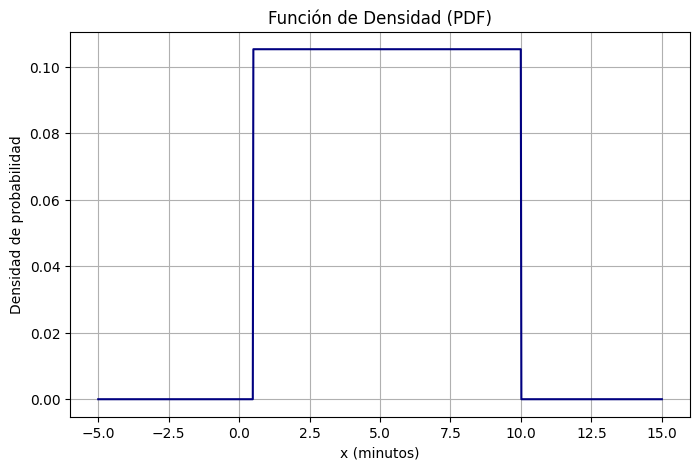

In [22]:
# Solución del ejercicio
from scipy.stats import uniform
# Parametros
a = 0.5
b = 10

# FUNCIÓN DE DENSIDAD Y GRÁFICA
# Crear el objeto de dist. unif usando scipy
unif_dist = sps.uniform(loc=a, scale=b-a)

# Generar valores de x
x = np.linspace(-5, 15, 1000)

# Calcular la función densidad
pdf_values = unif_dist.pdf(x)

# Graficar la PDF
plt.figure(figsize=(8, 5))
plt.plot(x, pdf_values, color='navy') # para cada gráfica
plt.xlabel('x (minutos)')
plt.ylabel('Densidad de probabilidad')
plt.title('Función de Densidad (PDF)')
plt.grid(True)
plt.show()

In [28]:
# Calcular la función de distribución
cdf_values = unif_dist.cdf(x)

# Calcular P (5<X < 8) = F(8) - F(5)
p_1 = unif_dist.cdf(8) - unif_dist.cdf(5)

# Imprimir los resultados
print(f"P (5 < X < 8) = {p_1}")

P (5 < X < 8) = 0.31578947368421056


La probabilidad de que el alumno espere entre $5$ y $8$ minutos es $31.58\%$

In [25]:
# ESPERANZA Y VARIANZA

# Calcular la esperanza
esperanza = (a+b)/2

# Calcular la varianza
varianza = ((b-a)**2)/12

# Imprimir los resultados
print(f"Esperanza = {esperanza}")
print(f"Varianza = {varianza}")

Esperanza = 5.25
Varianza = 7.520833333333333


El tiempo promedio de espera es de 5.25 min.

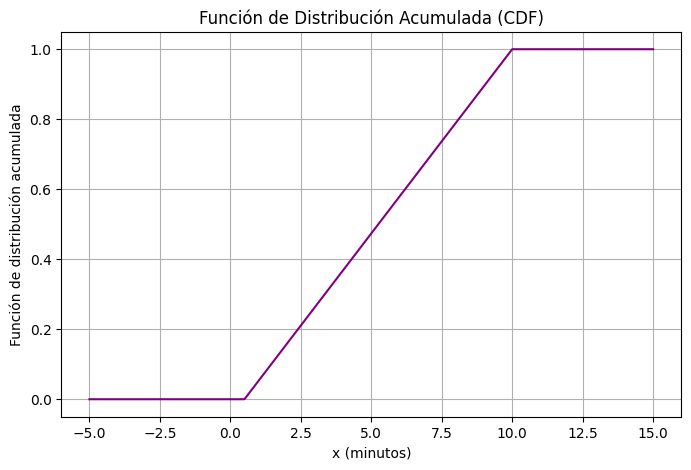

In [33]:
# Función de distribución
cdf_values = unif_dist.cdf(x)

# Graficar la CDF
plt.figure(figsize=(8, 5))
plt.plot(x, cdf_values, color='purple')
plt.xlabel('x (minutos)')
plt.ylabel('Función de distribución acumulada')
plt.title('Función de Distribución Acumulada (CDF)')
plt.grid(True)
plt.show()

In [34]:
# P(2.51 <= X <= 7.99) = F(7.99) - F(2.51)
p_2 = unif_dist.cdf(7.99) - unif_dist.cdf(2.51)

# Imprimir los resultados
print(f"P(2.51 <= X <= 7.99) = {p_2}")


P(2.51 <= X <= 7.99) = 0.576842105263158


La probabilidad de que el alumno espere entre $7.99$ y $2.51$ minutos es $57.68\%$

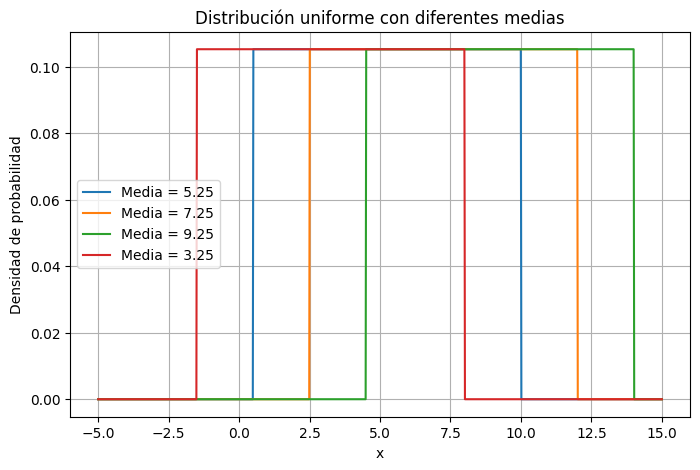

In [42]:
# Parámetros de distribuciones uniformes
intervalos = [(0.5, 10), (2.5, 12), (4.5, 14), (-1.5, 8)]

# Generar valores de x
x = np.linspace(-5, 15, 1000)

# Graficar las distribuciones
plt.figure(figsize=(8, 5))

for a, b in intervalos:
    unif_dist = uniform(loc=a, scale=b-a)
    pdf_values = unif_dist.pdf(x)

    # Calcular la media
    media = (a+b)/2

    plt.plot(x, pdf_values, label=f'Media = {media}')

plt.xlabel('x')
plt.ylabel('Densidad de probabilidad')
plt.title('Distribución uniforme con diferentes medias')
plt.grid(True)
plt.legend()
plt.show()

Cuando la media aumenta, la gráfica se desplaza hacia la izquierda, en caso contrario, hacia la izquierda.

## Variable aleatoria exponencial con parámetro $\lambda >0$.
La distribución exponencial es una de las distribuciones continuas más utilizadas. A menudo se utiliza para modelar el **tiempo** transcurrido entre eventos.  
Algunos ejemplos en los que podría utilizarse la distribución exponencial son:
* El tiempo transcurrido en un call center hasta recibir la primer llamada del día.
* El  tiempo entre terremotos de una determinada magnitud.
* Supongamos una máquina que produce hilo de alambre, la cantidad de metros de alambre hasta encontrar una falla en el alambre se podría modelar como una exponencial.

Se dice que la variable aleatoria $X$ tiene distribución exponecial de parámetro $\lambda>0$, si su función de densidad está dada por:
$$f_{X}(x)=\begin{cases}
\lambda e^{-\lambda x} & x>0\\
0 & \text{en otro caso}
\end{cases}$$

La esperanza y varianza son:
$$\mathbb{E}[X]= \frac{1}{\lambda}, Var(X)=\frac{1}{\lambda^2}$$


Notación. $X\sim Exp(\lambda).$
$\textbf{Propiedad de pérdida de memoria:}$
$$\mathbb{P}(X>t+s \mid X>t)=\mathbb{P}(X>s)=e^{-\lambda s}.$$
La esperanza y varianza de de una distribución exponencial de la forma $$f_{X}(x)=\begin{cases}
\frac{1}{\lambda} e^{-\frac{x}{\lambda}} & x>0\\
0 & \text{en otro caso}
\end{cases}$$:
$$\mathbb{E}[X]= \int_{0}^{\infty}xf_{x}(x)dx = \int_{0}^{\infty}x\frac{1}{\lambda}e^{-\frac{x}{\lambda}}dx = \lambda$$
y
\begin{align*}
\text{Var}(X) &= \mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} = \int_{0}^{\infty}x^{2}f_{x}(x)dx-\lambda^{2} \\ &= \int_{0}^{\infty}x^{2}\frac{1}{\lambda}e^{-\frac{x}{\lambda}}dx - \lambda^{2} = \lambda^{2}
\end{align*}

Propiedad de pérdida de memoria: si se conoce toda la información y se quiere conocer la probabilidad de que esa variable aleatoria $X$ sea mayor que $t$ con una variable adicional $s$.

**Ejemplo**

Consideremos la variable aleatoria $X$ como el tiempo (en minutos) entre la llegada de dos personas a la fila  de una sucursal bancaria.
Adicionalmente, el banco ha determinado que solo el $10\%$ de las veces, el tiempo que transcurre entre la llegada de una persona y otra es mayor a dos minutos.
Esto permite calcular el valor de $\lambda$, ya que
$$\mathbb{P}(X>2)=0.1$$
entonces
$$1-\mathbb{P}(X\le 2) = 1-F_{X}(2) = 0.1$$

Notemos que si $X\sim Exp\left( \lambda \right)$, entonces $F_{X})(x) = 1-e^{-\frac{x}{\lambda}}$
Por lo que $F_{X}(2)= 1-e^{\frac{-2}{\lambda}} =0.9$, entonces
$e^{\frac{-2}{\lambda}}=0.1$. Por lo que
$$\frac{-2}{\lambda}=\ln(0.1) \Rightarrow \lambda=0.87$$
Por lo tanto $X\sim\exp(0.87)$.

Ahora queremos calcular la probabilidad de que entre la llegada de una persona y otra transcurra por lo menos un minuto, lo cual puede calcularse de dos formas:
\begin{align*}
 \mathbb{P}(X>1) &= \int_{1}^{\infty}f_{X}(x)dx = \int_{1}^{\infty}\frac{1}{0.87}e^{\frac{-x}{0.87}}dx = 0.32
 \end{align*}
\begin{align*}
 \mathbb{P}(X>1) &= 1-\mathbb{P}(X\le 1) = 1-\left[1-e^{\frac{-1}{0.87}}\right] = -e^{\frac{-1}{0.87}}
\end{align*}

# Variable aleatoria normal con parámetros media $\mu$ y varianza $\sigma^{2}$.

La distribución normal es una de las más importantes y de mayor uso tanto en la teoría de la probabilidad, como en la teoría estadística.

También llamada distribución gaussiana, en honor a Gauss, a quien se considera el padre de ésta distribución.

La importancia de la distribución normal, radica en el famoso Teorema central del límite. Fue descubierta por De Moivre en 1733 como un límite de la distribución binomial.


La importancia de esta distribución radica en que permite modelar numerosos fenómenos naturales, sociales y psicológicos, por ejemplo:
* Estatura
* Efectos de un fármaco
* Consumo de cierto producto por un grupo de individuos
* Coeficiente intelectual
* Nivel de ruido en telecomunicaciones
* Errores cometidos al medir ciertas magnitudes

Además, esta distribución juega un papel de suma importancia en la inferencia estadística.

Se dice que la variable aleatoria $X$ tiene distribución normal de parámetros $\mu$ y $\sigma^{2}$, donde $\mu,\sigma\in\mathbb{R}$ y $\sigma>0$, si su función de densidad está dada por:
$$f_{X}(x)=\begin{cases}
	\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}} &\quad \text{si }  x \in\mathbb{R} \\
	\qquad 0 &\quad \text{e.o.c}  
\end{cases}$$

**Notación.** $X\sim N(\mu,\sigma^{2})$


Tal curva (**la campana de Gauss-Bell**) es una función que depende de los parámetros $\mu$ y $\sigma^{2}$.


**Observación:** El parámetro $\mu$ se llama *media* y el  parámetro $\sigma^{2}$ se llama *varianza*.

La función de densidad definida anteriormente es efecto función de densidad, ya que
$$\int_{\mathbb{R}}f_{X}(x)dx = \int_{\mathbb{R}}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(x-m)^{2}}{2\sigma^{2}}}  = 1 $$

Variable aleatoria normal con parámetros  0  y  1 .
La ley de $Z\sim N(0,1)$ está dada por la función de densidad
$$
f_{Z}(z) = \frac{1}{\sqrt{2\pi}}e^{-\frac{z^2}{2}},
$$
para $z\in \mathbb{R}$.

Sabemos que:
* La varianza es usada como una medida para comparar la dispersión en dos o más conjuntos de observaciones.
* Una desviación estándar pequeña indica que los valores de la variable aleatoria se encuentran cercanos a la media.
* Una desviación estándar grande indica que los valores de la variable aleatoria se dispersan mucho con respecto a la media.

La función de distribución de una variable aleatoria $X\sim N(\mu,\sigma^{2})$ está dada por:
$$F_{X}(x) = \int_{-\infty}^{x}\frac{1}{\sqrt{2\pi\sigma^{2}}}e^{-\frac{(y-\mu)^{2}}{2\sigma^{2}}}dy$$

Esta nos proporciona la probabilidad de que $X$ tome calores menores o iguales a un valor específico $x$, y corresponde al área bajo la curva en el intervalo $(-\infty,x]$:

No es sencillo calcular $F_{X}(x)$, pero cualquier v.a. gaussiana puede transformarse a una v.a. estandarizada. Existen tablas para esta v.a., lo cual hace los cálculos más fáciles.

**Proposición**  Sea $X\sim N(\mu,\sigma^{2})$, entonces
$$Z=\frac{X-\mu}{\sigma}$$
tiene una distribución gaussiana con media $0$ y varianza $1$, es decir, $Z\sim N(0,1)$.


**Demostración** 	Primero vamos a calcular la función de distribución de $Z$:
$$F_{Z}(z):=\mathbb{P}(Z\le z) = \mathbb{P}\left(\frac{X-\mu}{\sigma}\le z\right) = \mathbb{P}(X\le \sigma z + \mu) := F_{X}(\sigma z + \mu)$$
Entonces, la función de densidad de $Z$ esta dada por:
$$f_{Z}(z) = \frac{dF_{Z}(z)}{dz} = \frac{dF_{X}(\sigma z + \mu)}{dz} = \sigma f_{X}(\mu+\sigma z) = \frac{e^{-z^{2}/2}}{\sqrt{2\pi}}$$

Decimos que $X$ tiene distribución gaussiana estándar (normal estándar), $X\sim N(0,1)$, si su función de densidad esta dada por:
$$f_{X}(x)=\begin{cases}
	\frac{e^{-x^{2}/2}}{\sqrt{2\pi}} &\quad \text{si }  x \in\mathbb{R} \\
	\quad 0 &\quad \text{e.o.c}  
\end{cases}$$

Podemos calcular cualquier probabilidad de la forma
$$\mathbb{P}(a<X<b)$$
de la siguiente manera: para $z\ge 0$, definimos
$$\Phi(z) = \frac{1}{\sqrt{2\pi}}\int_{0}^{z}e^{-x^{2}/2}dx.$$


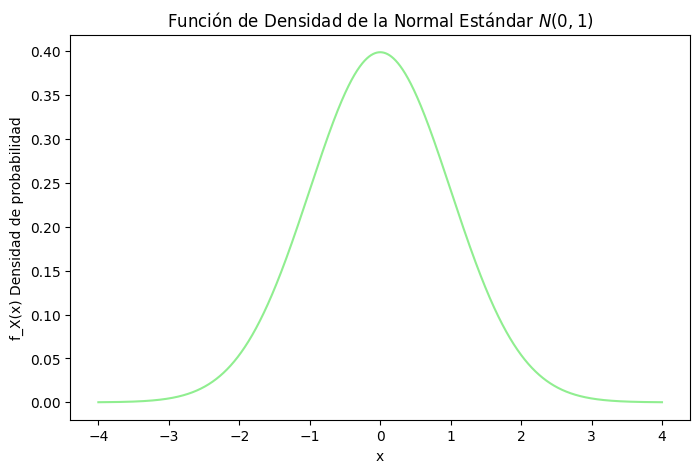

In [15]:
from scipy.stats import norm
# Generar los valores
x = np.arange(-4,4,0.001)

plt.figure(figsize=(8, 5))
plt.plot(x, norm.pdf(x), color='lightgreen')
plt.xlabel('x')
plt.ylabel('f_X(x) Densidad de probabilidad')
plt.title('Función de Densidad de la Normal Estándar $N(0,1)$')
plt.show()

Propiedades de la función de densidad de probabilidades de una distribución normal estándar:

1. Es positiva: $f(x)\geq 0$ para todo $x$ real.
2. Es continua y derivable en todas partes.
3. Es simétrica alrededor de $\mu$.
4. Conforme $x$ toma valores muy grandes de manera positiva y negativa, la función decrece hacia cero muy rápidamente.
5. Tiene un máximo global.
6. El área total bajo la curva es igual a $1$.

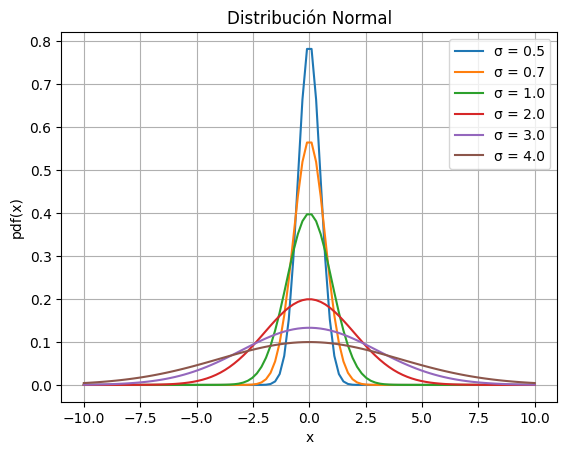

In [18]:
fig, ax = plt.subplots(1, 1)
x = np.linspace(-10,10,100) # Genero 100 puntos igualmente espaciados
# Creamos una lista con las desviaciones estándar
stdvs = [0.5, 0.7, 1.0, 2.0, 3.0, 4.0]
for s in stdvs:
  ax.plot(x, norm.pdf(x, scale = s), label = f'σ = {s:.1f}')
ax.set_xlabel('x')
ax.set_ylabel('pdf(x)')
ax.set_title('Distribución Normal')
ax.legend(loc = 'best', frameon = True)
plt.grid(True)
plt.show()

A medida que la varianza va creciendo, los datos se alejan más de la media